# **Name:Alisha khan**

# **week 5: Transfer Learning**

# **Part 1: The Data, and an Image as Numbers**

## **Task 1.1: Imports, GPU check, and class counts**

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("puneet6060/intel-image-classification")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/puneet6060/intel-image-classification


In [2]:
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)   # must say cuda; if not, turn on the GPU
ROOT = '/kaggle/input/datasets/puneet6060/intel-image-classification'
TRAIN_DIR = f'{ROOT}/seg_train/seg_train'
TEST_DIR = f'{ROOT}/seg_test/seg_test'
classes = sorted(os.listdir(TRAIN_DIR))
for c in classes:
    n_tr = len(os.listdir(os.path.join(TRAIN_DIR, c)))
    n_te = len(os.listdir(os.path.join(TEST_DIR, c)))
    print(f'{c:10s} train {n_tr:5d}   test {n_te:4d}')

Device: cuda
buildings  train  2191   test  437
forest     train  2271   test  474
glacier    train  2404   test  553
mountain   train  2512   test  525
sea        train  2274   test  510
street     train  2382   test  501


## **Task 1.2: Look at the images, then at the numbers**


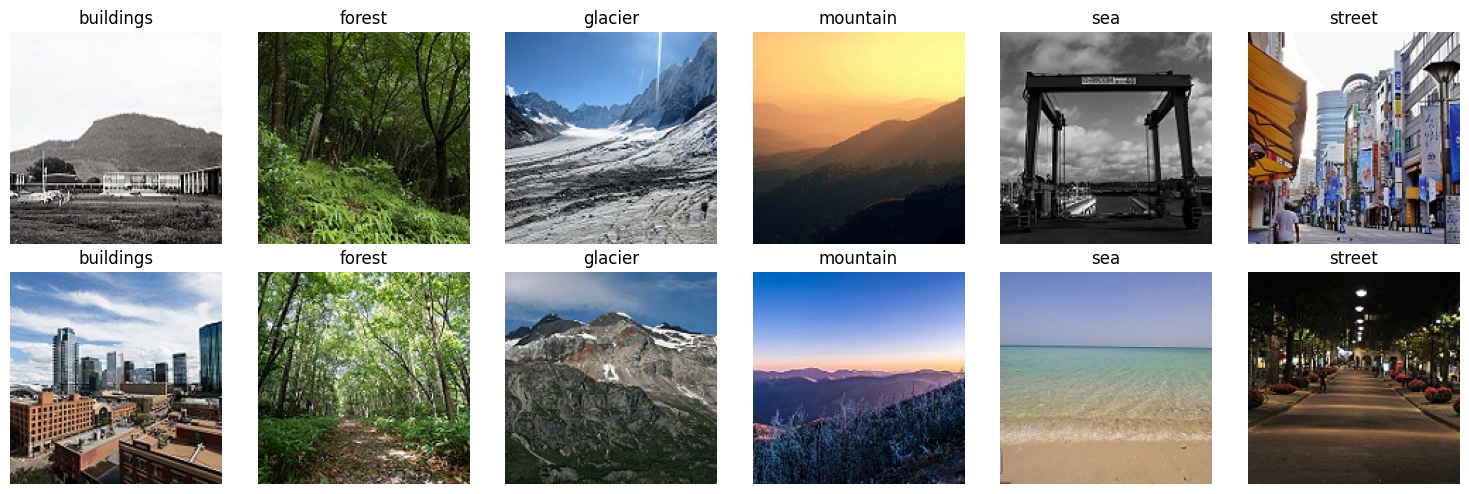

Shape (H, W, C): (150, 150, 3)  dtype: uint8  range: 0 to 255
Top-left 3x3 of the red channel:
 [[8 6 3]
 [6 5 4]
 [5 5 5]]


In [3]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j, c in enumerate(classes):
    files = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))[:2]
    for i, f in enumerate(files):
        img = Image.open(os.path.join(TRAIN_DIR, c, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(c)
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()
arr = np.array(img)
print('Shape (H, W, C):', arr.shape, ' dtype:', arr.dtype,
      ' range:', arr.min(), 'to', arr.max())
print('Top-left 3x3 of the red channel:\n', arr[:3, :3, 0])

# **write it answer**
## Similar Classes: The buildings and street classes look most visually similar by eye because both feature urban structures, man-made architecture, and concrete surfaces.
## Model Confusion Prediction: I predict that the model will confuse buildings and street the most during classification. This will be verified in Part 6.

# **Image Properties:**
## Shape (H, W, C): (150, 150, 3)   
## Data Type: uint8  
## Value Range: 0 to 255

# **Part 2: Convolution and Parameters by Hand **

## **Task 2.1: Reproduce the lecture's convolution**


tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])


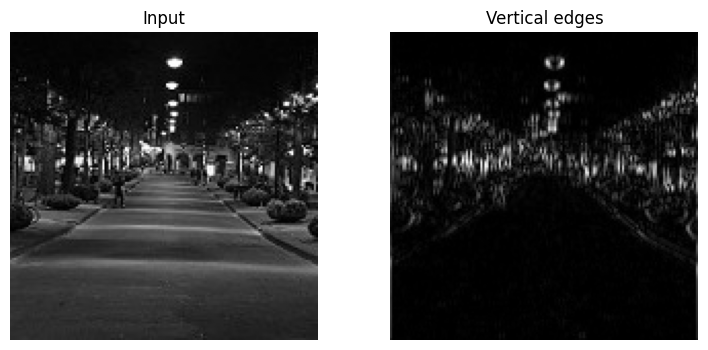

In [4]:
# The 5x5 example from the lecture: a vertical edge
x = torch.tensor([[0, 0, 10, 10, 10]] * 5, dtype=torch.float32)
k = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)
out = F.conv2d(x.view(1, 1, 5, 5), k.view(1, 1, 3, 3))
print(out.squeeze())            # expect three rows of [30, 30, 0]
# The same kernel on a real photo, converted to grayscale
g = transforms.functional.to_tensor(img.convert('L')).unsqueeze(0)
edges = F.conv2d(g, k.view(1, 1, 3, 3), padding=1)
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(g.squeeze(), cmap='gray')
ax[0].set_title('Input')
ax[1].imshow(edges.squeeze().abs(), cmap='gray')
ax[1].set_title('Vertical edges')
for a in ax:
    a.axis('off')
plt.show()

## **Task 2.2: Why convolutions, in numbers**


In [5]:
def count(m):
    return sum(p.numel() for p in m.parameters())
conv = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
dense = nn.Linear(150 * 150 * 3, 512)
print(f'Conv 3x3, 3 -> 64   : {count(conv):,} parameters')  # (3*3*3+1)*64
print(f'Dense 67,500 -> 512 : {count(dense):,} parameters')
t = torch.randn(1, 3, 224, 224)
for stride in [1, 2]:
    c = nn.Conv2d(3, 64, kernel_size=3, stride=stride, padding=1)
    print(f'stride {stride}: output {tuple(c(t).shape)}')  # (W-K+2P)/S + 1
print('2x2 max pool:', tuple(F.max_pool2d(t, 2).shape))

Conv 3x3, 3 -> 64   : 1,792 parameters
Dense 67,500 -> 512 : 34,560,512 parameters
stride 1: output (1, 64, 224, 224)
stride 2: output (1, 64, 112, 112)
2x2 max pool: (1, 3, 112, 112)


# **write it answer**

# **Arithmetic Calculations:**
## Convolution Layer (1,792 parameters): Calculated using the formula $(K \times K \times C_{in} + 1) \times C_{out}$, which gives $(3 \times 3 \times 3 + 1) \times 64 = (27 + 1) \times 64 = 28 \times 64 = 1,792$.

## Dense Layer (34,560,512 parameters): Calculated as $(\text{Inputs} \times \text{Outputs}) + \text{Bias}$, which gives $(67,500 \times 512) + 512 = 34,560,000 + 512 = 34,560,512$.  
## **Parameter Comparison**:The dense layer requires approximately 19,286 times more parameters than the $3 \times 3$ convolution layer ($34,560,512 / 1,792 \approx 19,286$).
## Weight Sharing Explanation:Weight sharing allows the exact same set of kernel weights to slide across all regions of the image, enabling the network to detect local features uniformly. Because the same filters are applied everywhere, the model can recognize a specific object or pattern regardless of where it appears in the image.

# **Part 3: Transforms and Data Loaders**

In [6]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet stats
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])
# Two views of the same folder: augmented for training, clean for validation
full_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)
idx = np.random.permutation(len(full_aug))
n_val = int(0.15 * len(idx))
train_ds = Subset(full_aug, idx[n_val:])
val_ds = Subset(full_eval, idx[:n_val])
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)
train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=128, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=128, num_workers=2)
print(len(train_ds), 'train |', len(val_ds), 'val |', len(test_ds), 'test')

11929 train | 2105 val | 3000 test


# **write it answer**
## Split Sizes:There are 11,929 training images, 2,105 validation images, and 3,000 test images.   Inappropriate Augmentations:
## For this scene dataset: RandomVerticalFlip would be wrong because scenes like buildings, mountains, and forests lose their natural orientation if inverted upside down.
## For handwritten digits: RandomHorizontalFlip would be wrong because flipping digits horizontally can change their meaning (e.g., turning a '6' into a '9' or altering letters like 'b' and 'd').

# **Part 4: The Training Loop and Feature Extraction **

## **Task 4.1: A reusable training loop**


In [7]:
def run_epoch(model, loader, optimizer=None):
    """One pass over the data. Trains only if an optimizer is given."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)                     # forward pass
            loss = F.cross_entropy(logits, yb)     # softmax + log loss
            if training:
                optimizer.zero_grad()
                loss.backward()                    # backpropagation
                optimizer.step()                   # gradient step
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n
def fit(model, optimizer, epochs, history):
    best_acc, best_state = -1.0, None
    for ep in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_dl, optimizer)
        va_loss, va_acc = run_epoch(model, val_dl)
        history.append((tr_loss, va_loss, tr_acc, va_acc))
        if va_acc > best_acc:
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
              f'val loss {va_loss:.3f} acc {va_acc:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)      # keep the best validation epoch
    return best_acc

## **Task 4.2: Freeze the body, train a new head**


In [10]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
    p.requires_grad = False                           # freeze the body
model.fc = nn.Linear(model.fc.in_features, len(classes))  # new 6-class head
model = model.to(device)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable {trainable:,} of {count(model):,} parameters')
history = []
opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, feature extraction: {best:.3f}')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 232MB/s]


Trainable 3,078 of 11,179,590 parameters
epoch 1: train loss 0.575 acc 0.816 | val loss 0.345 acc 0.887 (90s)
epoch 2: train loss 0.329 acc 0.889 | val loss 0.297 acc 0.898 (36s)
epoch 3: train loss 0.298 acc 0.895 | val loss 0.274 acc 0.907 (36s)
Best validation accuracy, feature extraction: 0.907


# **write it answer**
# **Validation Accuracy per Epoch:**
## Epoch 1: 88.7% (acc 0.887)  
## Epoch 2: 89.8% (acc 0.898) 
## Epoch 3: 90.7% (acc 0.907)  
## Best Validation Accuracy: 90.7% (Feature Extraction)  
## **High Accuracy with Only 0.03% Trainable Parameters**:Because the pre-trained ResNet-18 model has already learned powerful, generalized feature extractors (edges, textures, shapes, and complex object parts) in its earlier layers from ImageNet, the foundational hierarchy is already robust.By freezing the body and training only the final linear layer (the classification head), the model reuses these rich, pre-existing hierarchical features. The new head only needs to learn how to map those high-level representations to our 6 specific classes, enabling high accuracy while updating just 3,078 out of 11,179,590 parameters (0.03%).

# **Part 5: Fine-Tuning and Learning Curves**

## **Task 5.1: Unfreeze layer4 with a smaller learning rate**


In [11]:
for p in model.layer4.parameters():
    p.requires_grad = True                     # unfreeze the last block
opt = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-4},  # gentle: pretrained
    {'params': model.fc.parameters(), 'lr': 1e-3}])     # faster: new head
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable now: {trainable:,}')
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, fine-tuned: {best:.3f}')

Trainable now: 8,396,806
epoch 1: train loss 0.256 acc 0.912 | val loss 0.232 acc 0.928 (37s)
epoch 2: train loss 0.166 acc 0.940 | val loss 0.214 acc 0.931 (35s)
epoch 3: train loss 0.126 acc 0.955 | val loss 0.236 acc 0.929 (38s)
Best validation accuracy, fine-tuned: 0.931


## **Task 5.2: Plot the learning curves**


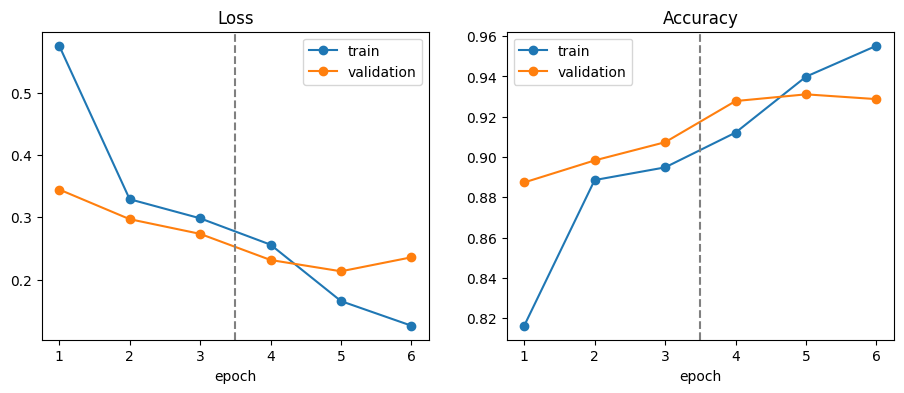

In [12]:
h = np.array(history)
ep = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h[:, 0], 'o-', label='train')
ax[0].plot(ep, h[:, 1], 'o-', label='validation')
ax[1].plot(ep, h[:, 2], 'o-', label='train')
ax[1].plot(ep, h[:, 3], 'o-', label='validation')
for a, title in zip(ax, ['Loss', 'Accuracy']):
    a.axvline(3.5, color='gray', ls='--')   # where fine-tuning starts
    a.set_title(title)
    a.set_xlabel('epoch')
    a.legend()
plt.show()

# **write it answer**
## **Improvement in Validation Accuracy:**
## Yes, fine-tuning improved the best validation accuracy from 90.7% (feature extraction) to 93.1% (fine-tuned), which is an absolute improvement of 2.4%. 
## **Curve Description & Overfitting Check:**
## The curves show that during the first 3 epochs (feature extraction), both training and validation losses decrease steadily while accuracies increase. After the vertical dashed line (where fine-tuning begins at epoch 4), the training loss continues to drop sharply and training accuracy rises.However, looking at epochs 5 and 6, there are clear signs of overfitting: the validation loss stops decreasing and starts rising (from 0.214 to 0.236), and validation accuracy plateaus/drops slightly while training loss keeps falling.
## **Why Training Accuracy is Lower than Validation Accuracy:**
## Training accuracy is lower than validation accuracy because strong data augmentations (such as RandomResizedCrop and ColorJitter) are applied exclusively to the training set to make the learning task harder and prevent overfitting. Meanwhile, the validation set uses clean, unaugmented resized images (Resize), making it an easier evaluation task during training

# **Part 6: Test Once, Then Study the Errors **

## **Task 6.1: Test-set evaluation**


Test accuracy: 0.925
              precision    recall  f1-score   support

   buildings      0.935     0.922     0.929       437
      forest      0.996     0.994     0.995       474
     glacier      0.942     0.799     0.865       553
    mountain      0.831     0.937     0.881       525
         sea      0.933     0.980     0.956       510
      street      0.938     0.934     0.936       501

    accuracy                          0.925      3000
   macro avg      0.929     0.928     0.927      3000
weighted avg      0.928     0.925     0.925      3000



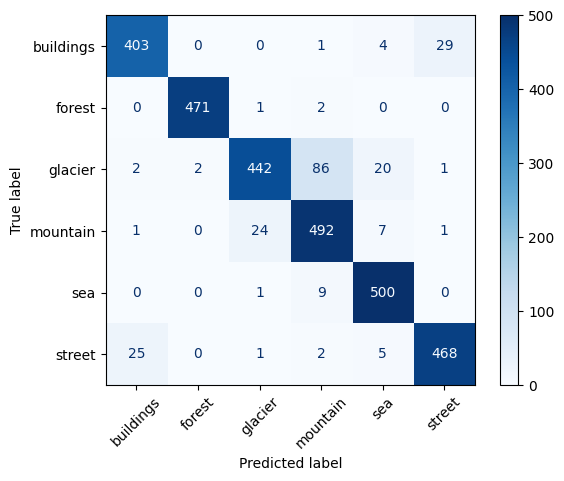

In [13]:
model.eval()
probs, preds, labels = [], [], []
with torch.no_grad():
    for xb, yb in test_dl:
        p = F.softmax(model(xb.to(device)), dim=1).cpu()
        probs.append(p)
        preds.append(p.argmax(1))
        labels.append(yb)
probs, preds, labels = torch.cat(probs), torch.cat(preds), torch.cat(labels)
print(f'Test accuracy: {(preds == labels).float().mean():.3f}')
print(classification_report(labels, preds, target_names=classes, digits=3))
cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(
    cmap='Blues', xticks_rotation=45)
plt.show()

## **Task 6.2: Error gallery**


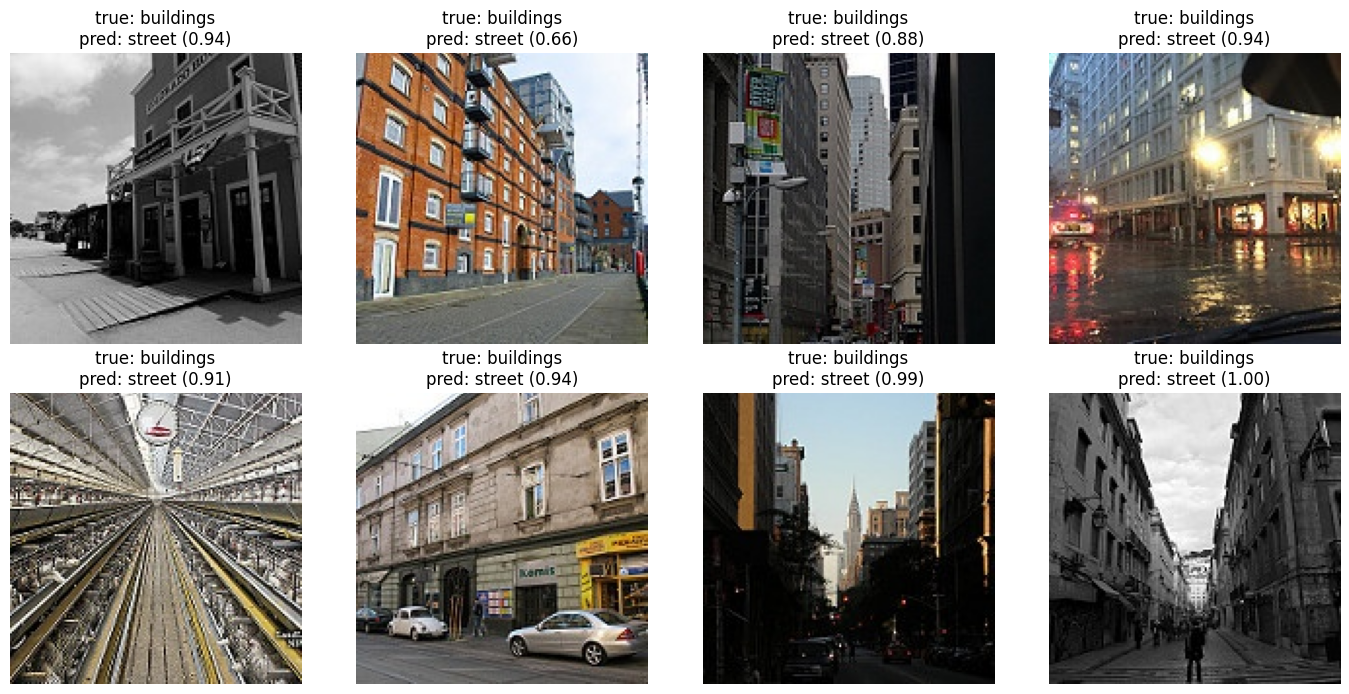

In [14]:
wrong = torch.where(preds != labels)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flat:
    ax.axis('off')
for ax, i in zip(axes.flat, wrong.tolist()):
    path, _ = test_ds.samples[i]
    ax.imshow(Image.open(path))
    ax.set_title(f'true: {classes[labels[i]]}\n'
                 f'pred: {classes[preds[i]]} ({probs[i].max():.2f})')
plt.tight_layout()
plt.show()

## **Task 6.3: Inside one prediction**


In [15]:
x0, y0 = test_ds[0]
with torch.no_grad():
    logits = model(x0.unsqueeze(0).to(device)).cpu().squeeze()
p = F.softmax(logits, dim=0)
print('True class:', classes[y0])
for c, z, q in zip(classes, logits.tolist(), p.tolist()):
    print(f'{c:10s} logit {z:6.2f}   probability {q:.3f}')

True class: buildings
buildings  logit   8.04   probability 1.000
forest     logit  -9.17   probability 0.000
glacier    logit  -4.34   probability 0.000
mountain   logit  -4.46   probability 0.000
sea        logit  -5.09   probability 0.000
street     logit  -2.57   probability 0.000


# **write it answer**
## **Test Accuracy & Weakest Classes:**
## Test Accuracy: 92.5% ($0.925$). 
## Two Weakest Classes by Recall: Glacier (recall: $0.799$) and Buildings (recall: $0.922$).
## Model Confusion & Task 1.2 Prediction:The pair confused most by the model is Glacier and Mountain (with 86 instances where glaciers were misclassified as mountains).
## My initial prediction from Task 1.2 (that buildings and street would be confused the most) was incorrect; although buildings and street had some overlap (29 confusions), glacier and mountain experienced the highest confusion due to their shared snowy, icy, and rocky high-altitude visual textures. 
## **Error Gallery Analysis:**
## **Error 1 (First image, true: buildings, pred: street):** The image is genuinely ambiguous; it shows a building facade featuring a storefront awning and a clear sidewalk/street-level view, creating an overlapping visual context between both classes.
## **Error 2 (Second image, true: buildings, pred: street):** The image is genuinely ambiguous; it depicts a tall brick building lining a narrow urban street with visible pavement and road perspective, combining key features of both categories

# **Part 7: Save and Share **

In [16]:
path = '/kaggle/working/resnet18_intel.pt'
torch.save(model.state_dict(), path)
print(f'Saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)')

Saved /kaggle/working/resnet18_intel.pt (44.8 MB)


# Check Your Understanding (Lab Answers)

## **1. Why does a network without nonlinear activations collapse to a single linear layer?**

## * **Answer:** Matrix multiplication is linear. When you compose multiple linear layers without nonlinear activation functions in between, the mathematical combination of successive weights and biases can always be simplified into a single equivalent linear transformation ($W_2(W_1x + b_1) + b_2 = (W_2W_1)x + (W_2b_1 + b_2)$), reducing the deep network to a basic single-layer linear model.

## **2. For logits [3, 1, 0], what probability does softmax give the first class?**

## * **Working & Calculation:**
## * Softmax formula: $P(i) = \frac{e^{z_i}}{\sum e^{z_j}}$
## * Exponents: $e^3 \approx 20.086$, $e^1 \approx 2.718$, $e^0 = 1.000$
## * Sum of exponents = $20.086 + 2.718 + 1.000 = 23.804$
## * Probability for the first class = $\frac{20.086}{23.804} \approx \mathbf{0.844}$ (or **84.4%**)



## **3. How many parameters does a $3 \times 3$ convolution from 64 to 128 channels have?**

## * **Working & Calculation:**
## * Formula: $(K \times K \times C_{in} + 1) \times C_{out}$
## * Plugging in values: $(3 \times 3 \times 64 + 1) \times 128$
## * $= (576 + 1) \times 128 = 577 \times 128 = \mathbf{73,856}$ **parameters**



## **4. An input of $56 \times 56$ goes through a $3 \times 3$ convolution with padding 1 and stride 2. What is the output size?**

## * **Working & Calculation:**
## * Formula: $\text{Output Size} = \lfloor \frac{W - K + 2P}{S} \rfloor + 1$
## * Plugging in values: $\lfloor \frac{56 - 3 + 2(1)}{2} \rfloor + 1$
## * $= \lfloor \frac{55}{2} \rfloor + 1 = 27 + 1 = \mathbf{28 \times 28}$



## **5. Why does a residual (skip) connection help gradients reach the early layers?**

## * **Answer:** Residual connections introduce a shortcut identity path (`+ x`) that bypasses the convolutional layers. During backpropagation, the derivative of the block becomes $\frac{\partial F(x)}{\partial x} + 1$. The explicit `+ 1` term ensures that the gradient can flow uninterrupted directly back to earlier layers, preventing the vanishing gradient problem in deep networks.

## **6. When would you train a CNN from scratch instead of using transfer learning?**

## * **Answer:** You would train from scratch when your target domain is drastically different from natural images (such as medical X-rays, MRI scans, seismic data, or highly specialized infrared/satellite imagery) where ImageNet feature extractors offer little relevance, or when you have massive amounts of domain-specific data and sufficient compute resources.